In [123]:
import seaborn as sns
import torch
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from torch import nn, optim
import numpy as np
import pandas as pd

# 난수 시드 고정
torch.manual_seed(42)

### 선형 회귀 실습 문제

# Tips Dataset
: 레스토랑의 총 식사 금액을 이용해 손님이 지불할 팁 금액을 예측하는 선형 회귀 모델 구현.

#### Step1. 데이터 불러오기 및 전처리

**사용 데이터: Tips Dataset**

- 데이터: 244개
- 입력 특징: 1개 (총 식사 금액 (`total_bill`))
- 정답: 팁 금액(`tip`)

| 열 이름 | 의미 | 설명 |
|:---:|:---:|:---|
| `total_bill` | 총 식사 금액 | 식사에 청구된 총 금액 |
| `tip` | 팁 금액 | 종업원에게 지불한 팁 |
| `sex` | 성별 | 계산한 손님의 성별 |
| `smoker` | 흡연 여부 | 흡연자 여부 |
| `day` | 요일 | 식사한 요일 |
| `time` | 식사 시간 | Lunch 또는 Dinner |
| `size` | 인원수 | 테이블의 손님 수 |

**실습 조건**
- 입력값(X): `total_bill`
- 정답(y): `tip`
- 결측치가 있는지 확인하고, 필요한 경우 처리한다.
- 학습 데이터와 테스트 데이터를 8:2 비율로 분리한다.
- 입력값은 학습 데이터의 평균과 표준편차를 이용해 표준화한다.
- `total_bill`과 `tip`의 관계를 산점도로 먼저 확인한다.

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


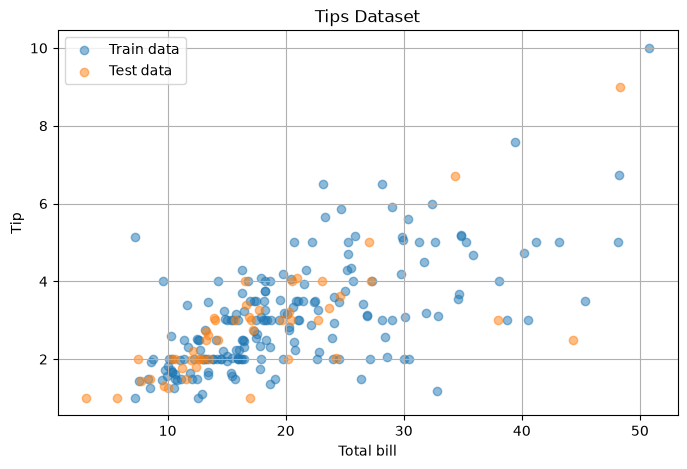

In [124]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"

df = pd.read_csv(url)
# 이번 실습에 필요한 두 열만 사용
df = df[['total_bill', 'tip']].dropna().copy()

data = sns.load_dataset('tips')

x = torch.tensor(data[['total_bill']].values, dtype = torch.float32)
y = torch.tensor(data[['tip']].values, dtype = torch.float32)

print(data.isnull().sum())

indices = torch.randperm(len(x))
train_size = int(len(x)*0.8)

train_indices = indices[:train_size]
test_indices = indices[train_size:]

x_train = x[train_indices]
x_test = x[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

mean = x_train.mean(dim=0)
std = x_train.std(dim=0).clamp(1e-8)

x_train_scaled = (x_train-mean)/std
x_test_scaled = (x_test-mean)/std

plt.figure(figsize=(8,5))

plt.scatter(x_train, y_train, alpha=0.5, label = 'Train data')
plt.scatter(x_test, y_test, alpha=0.5, label = 'Test data')

plt.xlabel('Total bill')
plt.ylabel('Tip')
plt.title('Tips Dataset')
plt.legend()
plt.grid(True)


#### Step2. 모델 만들기

- 입력 노드: 1개 (`total_bill`)
- 출력 노드: 1개 (`tip`)
- 활성화 함수: 사용하지 않음
- 모델: `nn.Linear`

In [125]:
model = nn.Linear(1,1)

#### STEP 3. 모델 학습시키기

- Optimizer: SGD
- Loss function: MSELoss
- 학습률(LR): 0.01부터 시작
- Epoch: 200
- Batch size: 32

In [126]:
LR=1e-2
EPOCH = 200
BATCH_SIZE = 32

train_DS = TensorDataset(x_train_scaled, y_train)
test_DS = TensorDataset(x_test_scaled, y_test)

train_DL= DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle = True)
test_DL = DataLoader(test_DS, batch_size = BATCH_SIZE, shuffle = False)

N = len(train_DL.dataset)


In [127]:
optimizer = optim.SGD(model.parameters(), lr=LR)
criterion = nn.MSELoss()

loss_history=[]

model.train()
for ep in range(EPOCH):
    rloss=0

    for x_batch, y_batch in train_DL:
        y_hat = model(x_batch)

        loss = criterion(y_hat, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        rloss += loss.item() * x_batch.shape[0]

    loss_e = rloss/N
    loss_history.append(loss_e)

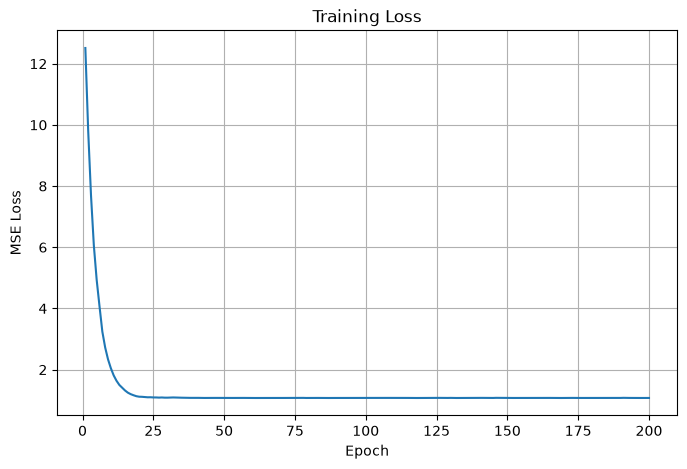

In [128]:
plt.figure(figsize = (8,5))
plt.plot(range(1, EPOCH +1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training Loss')
plt.grid()

#### Step4. 모델 테스트하기


In [129]:
model.eval()
with torch.no_grad():
    y_pred = model(x_test_scaled)

test_loss = criterion(y_pred, y_test).item()
test_rmse = np.sqrt(test_loss)

print(f'Test MSE : {test_loss:.3f}')


Test MSE : 0.893


#### Step5. 테스트 결과 시각화

**문제**
- 첫 번째 그래프: 테스트 데이터의 실제 산점도와 모델의 예측 회귀선을 함께 표시.
- 두 번째 그래프: 실제 팁 금액을 x축, 예측 팁 금액을 y축으로 하는 산점도를 작성.
- 두 번째 그래프에 완벽한 예측을 나타내는 기준선(y=x)을 추가.
- 그래프의 축 이름과 제목을 적절히 표시.

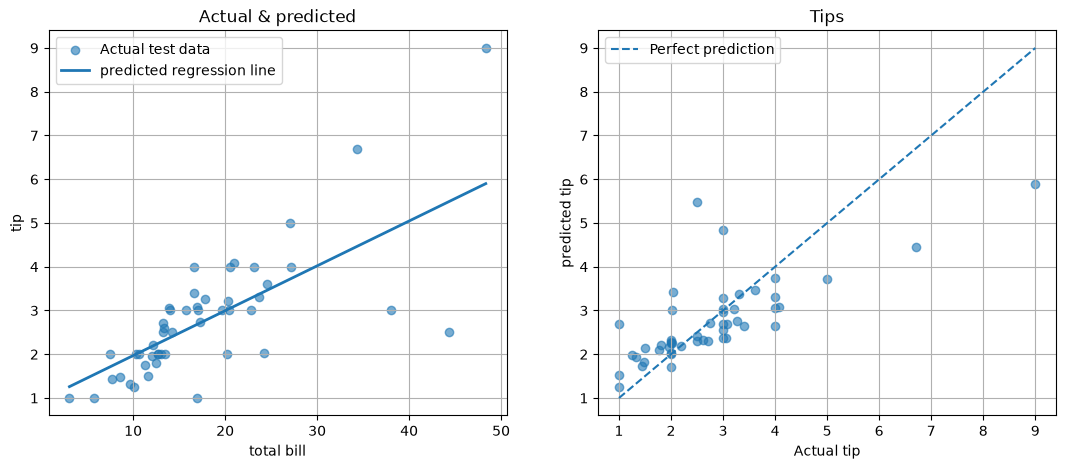

In [130]:
model.eval()
with torch.no_grad():
    y_pred = model(x_test_scaled)

sort_idx = torch.argsort(x_test.squeeze())
x_test_sorted = x_test[sort_idx]
x_test_scaled_sorted = x_test_scaled[sort_idx]
y_test_sorted = y_test[sort_idx]

with torch.no_grad():
    y_pred_sorted = model(x_test_scaled_sorted)

fig, axes = plt.subplots(1,2,figsize = (13,5))

axes[0].scatter(x_test.numpy(), y_test.numpy(), alpha = 0.6, label = 'Actual test data')
axes[0].plot(x_test_sorted.numpy(), y_pred_sorted.numpy(), linewidth=2, label = 'predicted regression line')
axes[0].set_xlabel('total bill')
axes[0].set_ylabel('tip')
axes[0].set_title('Actual & predicted')
axes[0].legend()
axes[0].grid(True)

axes[1].scatter(y_test.numpy(), y_pred.numpy(), alpha = 0.6)
min_val = min(y_test.min().item(), y_pred.min().item())
max_val = max(y_test.max().item(), y_pred.max().item())
axes[1].plot([min_val, max_val],[min_val,max_val], linestyle='--', label = 'Perfect prediction')
axes[1].set_xlabel('Actual tip')
axes[1].set_ylabel('predicted tip')
axes[1].set_title('Tips')
axes[1].legend()
axes[1].grid(True)



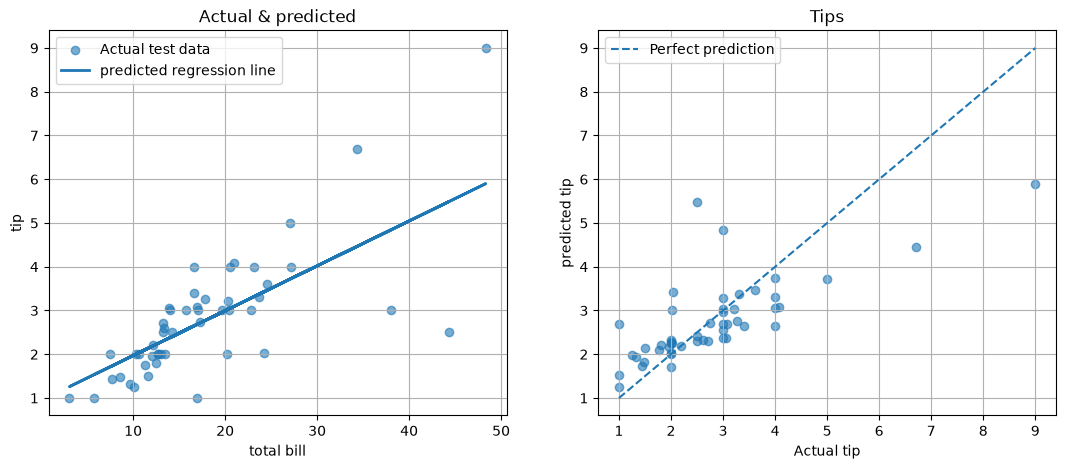

In [131]:
model.eval()
with torch.no_grad():
    y_pred = model(x_test_scaled)

fig, axes = plt.subplots(1,2,figsize = (13,5))

axes[0].scatter(x_test, y_test, alpha = 0.6, label = 'Actual test data')
axes[0].plot(x_test, y_pred, linewidth=2, label = 'predicted regression line')
axes[0].set_xlabel('total bill')
axes[0].set_ylabel('tip')
axes[0].set_title('Actual & predicted')
axes[0].legend()
axes[0].grid(True)

axes[1].scatter(y_test, y_pred, alpha = 0.6)
min_val = min(y_test.min().item(), y_pred.min().item())
max_val = max(y_test.max().item(), y_pred.max().item())
axes[1].plot([min_val, max_val],[min_val,max_val], linestyle='--', label = 'Perfect prediction')
axes[1].set_xlabel('Actual tip')
axes[1].set_ylabel('predicted tip')
axes[1].set_title('Tips')
axes[1].legend()
axes[1].grid(True)

#### STEP 6. 파라미터 개수 확인

In [132]:
total_prams =  sum(p.numel() for p in model.parameters())
print('파라미터 개수 : ',total_prams)

파라미터 개수 :  2
